# E-mail campaign experiment readout

I used the Hillstrom / MineThatData experiment to work through an A/B readout: design checks, effect sizes,
power, CUPED, and repeated monitoring. There are 64,000 customers and three randomized arms, with visit,
conversion, and spend measured over the next two weeks.

This notebook reads the generated report and recomputes the tests, bootstrap intervals, and CUPED values
with its recorded parameters. The assertions keep the notebook and command-line analysis in sync.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / 'abtest').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
from abtest import stats as S
from abtest.data import load, pre_covariates

res = json.loads((root / 'reports/results.json').read_text())
params = res['parameters']
df = load()
X = pre_covariates(df)
assert len(df) == res['dataset']['rows']
df.groupby('arm')[['visit', 'conversion', 'spend']].agg(['mean', 'std', 'count']).round(4)

visit                conversion                  spend           \
           mean     std  count       mean     std  count    mean      std   
arm                                                                         
control  0.1062  0.3081  21306     0.0057  0.0755  21306  0.6528  11.5882   
mens     0.1828  0.3865  21307     0.0125  0.1112  21307  1.4226  17.7542   
womens   0.1514  0.3584  21387     0.0088  0.0936  21387  1.0772  15.1161   

                
         count  
arm             
control  21306  
mens     21307  
womens   21387

## 1. Assignment counts and power
The SRM check uses the designed equal three-way allocation. Power uses the control rate as a planning baseline.

In [2]:
srm = S.srm_check(df.arm.value_counts().to_dict())
np.testing.assert_allclose(srm['p_value'], res['srm']['p_value'])
c = df[df.arm == 'control']
n = int(df.arm.value_counts().min())
np.testing.assert_allclose(S.mde_proportions(c.visit.mean(), n), res['power']['mde_visit_abs_at_n'])
display(pd.Series(srm))
pd.Series(res['power'])

counts          {'womens': 21387, 'mens': 21307, 'control': 21...
expected        {'womens': 21333.3, 'mens': 21333.3, 'control'...
chi2                                                     0.202531
p_value                                                  0.903693
srm_detected                                                False
dtype: object

baseline_visit_rate                        0.106167
n_per_arm_available                    21306.000000
mde_visit_abs_at_n                         0.008362
n_per_arm_for_1pp_visit_lift           15504.000000
n_per_arm_for_0.1pp_conversion_lift    96971.000000
n_per_arm_for_$0.25_spend_lift         33729.000000
dtype: float64

## 2. Fixed-horizon effects

Binary outcomes use two-proportion z-tests and Wald intervals for the absolute rate difference. Spend uses
Welch's t-test. Bootstrap intervals resample customers independently within each arm, using 4,000 draws
and seed 42. The 95% intervals are marginal; Holm adjusts the six fixed-horizon p-values as one family.

In [3]:
rows = []
for arm in ['mens', 'womens']:
    sub = df[df.arm.isin([arm, 'control'])]
    t = (sub.arm == arm).to_numpy()
    for metric in ['visit', 'conversion', 'spend']:
        y = sub[metric].to_numpy(float)
        key = f'{arm}_vs_control/{metric}'
        saved = res['tests'][key]
        test = S.two_proportion_ztest(y[t], y[~t], metric) if metric != 'spend' else S.welch_ttest(y[t], y[~t], metric)
        for field in ['control', 'treatment', 'diff', 'ci_low', 'ci_high', 'p_value']:
            np.testing.assert_allclose(getattr(test, field), saved['fixed'][field], rtol=1e-12, atol=0)
        for relative, field in [(False, 'bootstrap_ci_diff'), (True, 'bootstrap_ci_rel_lift')]:
            boot = S.bootstrap_diff_ci(y[t], y[~t], n_boot=params['bootstrap_reps'], seed=params['seed'], relative=relative)
            np.testing.assert_allclose(boot, saved[field], rtol=1e-12, atol=0)
        rows.append({'comparison': key, **test.dict(), 'bootstrap_abs': saved['bootstrap_ci_diff'],
                     'bootstrap_relative': saved['bootstrap_ci_rel_lift'], 'holm_p': res['holm_adjusted_p'][key]})
tab = pd.DataFrame(rows)
adjusted = S.holm(dict(zip(tab.comparison, tab.p_value)))
np.testing.assert_allclose([adjusted[k] for k in tab.comparison], tab.holm_p, rtol=1e-12, atol=0)
print('Verified all 6 fixed-horizon results and both bootstrap intervals per comparison.')
tab[['comparison', 'control', 'treatment', 'diff', 'ci_low', 'ci_high', 'holm_p', 'bootstrap_relative']]

Verified all 6 fixed-horizon results and both bootstrap intervals per comparison.


,comparison,control,treatment,diff,ci_low,ci_high,holm_p,bootstrap_relative
0,mens_vs_control/visit,0.106167,0.182757,0.076590,0.069954,0.083226,3.411099e-111,"[0.642564, 0.806699]"
1,mens_vs_control/conversion,0.005726,0.012531,0.006805,0.005000,0.008610,6.092894e-13,"[0.769687, 1.723287]"
2,mens_vs_control/spend,0.652789,1.422617,0.769827,0.485140,1.054515,3.491445e-07,"[0.63645, 1.943755]"
3,womens_vs_control/visit,0.106167,0.151400,0.045233,0.038894,0.051572,1.591202e-43,"[0.356295, 0.501288]"
4,womens_vs_control/conversion,0.005726,0.008837,0.003111,0.001499,0.004723,3.142103e-04,"[0.230616, 0.953377]"
5,womens_vs_control/spend,0.652789,1.077202,0.424412,0.168957,0.679868,1.129397e-03,"[0.218033, 1.278735]"


## 3. CUPED

The covariates describe customers before the campaign: past spend, recency, earlier product-line purchases,
new-customer status, ZIP category, and channel. The adjustment is fitted on the pooled treatment/control
sample. The reported variance reduction is the in-sample residual reduction; Welch intervals compare the
adjusted group means. Weak prediction of the two-week outcomes leaves only a small precision gain.

In [4]:
cuped_rows = []
for arm in ['mens', 'womens']:
    sub = df[df.arm.isin([arm, 'control'])]
    t = (sub.arm == arm).to_numpy()
    xs = X.loc[sub.index].to_numpy()
    for metric in ['visit', 'conversion', 'spend']:
        y = sub[metric].to_numpy(float)
        key = f'{arm}_vs_control/{metric}'
        entry = {'comparison': key}
        for name, covariates in [('cuped_history', xs[:, [0]]), ('cuped_multi', xs)]:
            adjusted_y = S.cuped_adjust(y, covariates)
            test = S.welch_ttest(adjusted_y[t], adjusted_y[~t])
            reduction = S.variance_reduction(y, adjusted_y)
            saved = res['tests'][key][name]
            np.testing.assert_allclose([test.diff, test.ci_low, test.ci_high, reduction],
                                       [saved['diff'], saved['ci_low'], saved['ci_high'], saved['variance_reduction']],
                                       rtol=1e-12, atol=1e-14)
            entry[name + '_variance_reduction'] = reduction
        entry['ci_width_ratio'] = res['tests'][key]['cuped_multi']['ci_width_ratio']
        cuped_rows.append(entry)
print('Verified history and multivariate CUPED for all 6 comparisons.')
pd.DataFrame(cuped_rows).round(5)

Verified history and multivariate CUPED for all 6 comparisons.


,comparison,cuped_history_variance_reduction,cuped_multi_variance_reduction,ci_width_ratio
0,mens_vs_control/visit,0.00444,0.02906,0.98532
1,mens_vs_control/conversion,0.00089,0.00228,0.99892
2,mens_vs_control/spend,0.00044,0.00131,0.99935
3,womens_vs_control/visit,0.00401,0.02586,0.98696
4,womens_vs_control/conversion,0.00068,0.00179,0.99916
5,womens_vs_control/spend,0.00038,0.00079,0.99961


## 4. Sequential replay and A/A calibration

The data contains no arrival timestamps, so the replay independently shuffles each arm with seed 42.
The Gaussian mSPRT uses a fixed 0.10 planning visit rate (`sigma2=0.09`) and an effect-prior SD of 1 pp
(`tau2=0.0001`). Its exact always-valid result assumes Gaussian observations with known common variance;
visits use the Gaussian approximation. The A/A experiment reports empirical rejection frequencies over
400 control-group splits at 20 looks, with an independent seed 43 and Monte Carlo intervals.

In [5]:
rng = np.random.default_rng(params['seed'])
t_all = df[df.arm == 'mens'].visit.to_numpy(float)
t = t_all[rng.permutation(len(t_all))][:n]
control = c.visit.to_numpy(float)[rng.permutation(len(c))][:n]
pv = S.msprt_pvalues(t, control, tau2=res['sequential']['tau2'], sigma2=res['sequential']['sigma2'])
crossing = int(np.flatnonzero(pv < params['alpha'])[0]) + 1 if (pv < params['alpha']).any() else None
assert crossing == res['sequential']['stopped_at_n_per_arm']
np.testing.assert_allclose(pv[-1], res['sequential']['final_running_p'], rtol=1e-12, atol=0)
display(pd.Series(res['sequential']))
res['aa_simulation']

method                     Gaussian mSPRT approximation, mens vs control,...
tau2                                                                  0.0001
sigma2                                                                  0.09
parameter_selection        fixed planning baseline 0.10 and effect-prior ...
arrival_order              seeded independent random permutation of each arm
stopped_at_n_per_arm                                                     372
fraction_of_full_sample                                              0.01746
final_running_p                                                          0.0
dtype: object

{'n_sims': 400,
 'looks': 20,
 'fixed_horizon_fpr': 0.045,
 'naive_peeking_fpr': 0.22,
 'msprt_peeking_fpr': 0.0125,
 'rejections': {'fixed_horizon': 18, 'naive_peeking': 88, 'gaussian_msprt': 5},
 'rejection_rate_ci95': {'fixed_horizon': [0.026884625615141773,
   0.07018879549534222],
  'naive_peeking': [0.18035595725209105, 0.26384331582750836],
  'gaussian_msprt': [0.004070835844599721, 0.028928343785286817]}}

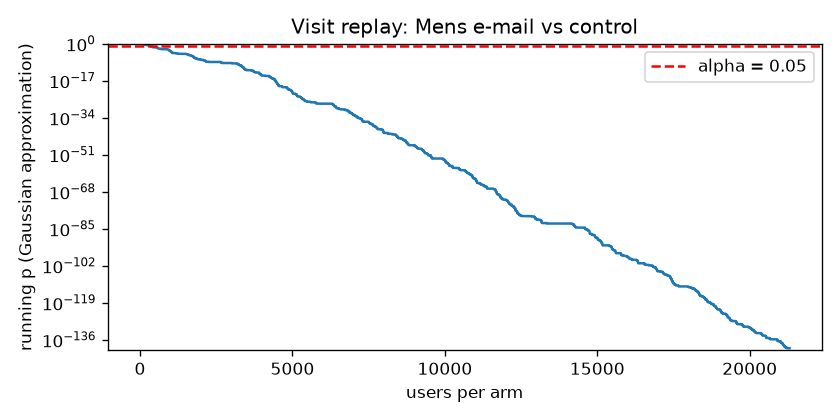

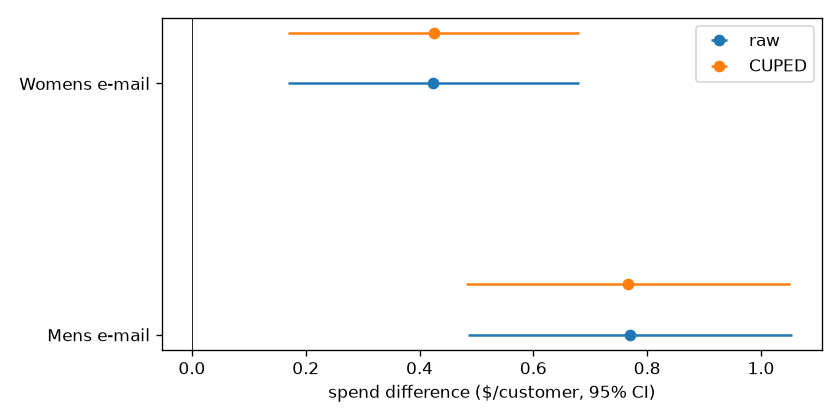

All notebook/report consistency checks passed.


In [6]:
display(Image(filename=str(root / 'reports/figures/msprt_visit.png')))
display(Image(filename=str(root / 'reports/figures/cuped_spend_ci.png')))
print('All notebook/report consistency checks passed.')